<a href="https://colab.research.google.com/github/Nameloc14/DonovanColemanCOMP3800Project2/blob/main/project2usedcarprice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project #2: Predicting Used Car Prices
Course: COMP-3800 Data Analytics  |  Student: Donovan Coleman

Dataset: Used Car Price Prediction Dataset (Kaggle, by taeefnajib) – listings scraped from cars.com.
Type of problem: Regression (target = price)

# 1. Problem Statement

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

## 1.1 Load the data

In [ ]:
# In Colab: upload used_cars.csv to the session first
df = pd.read_csv('used_cars.csv')
df.shape

(4009, 12)

## 1.2 First look at the rows

In [ ]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


## 1.3 Column types and non-null counts

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB


## 1.4 Describing the dataset
The dataset has 4,009 used-car listings and 12 columns:

| Column | Meaning |
|---|---|
| brand, model | Make and trim of the car |
| model_year | Year the car was built |
| milage | Odometer reading (text such as "51,000 mi.") |
| fuel_type | Gasoline, Hybrid, Diesel, E85 Flex Fuel, Electric, etc. |
| engine | Text description (horsepower, size, cylinders) |
| transmission | Transmission description (62 different spellings) |
| ext_col, int_col | Exterior and interior color |
| accident | Whether an accident or damage was reported |
| clean_title | Whether the car has a clean title |
| price | Listing price in dollars (stored as text like "$10,300") – the target |

## 1.5 Analyze the target variable: convert price to a number

In [ ]:
df['price'] = df['price'].str.replace('[$,]', '', regex=True).astype(float)
df['price'].describe().round(0)

,price
count,4009.0
mean,44553.0
std,78711.0
min,2000.0
25%,17200.0
50%,31000.0
75%,49990.0
max,2954083.0


## 1.6 Shape of the target distribution

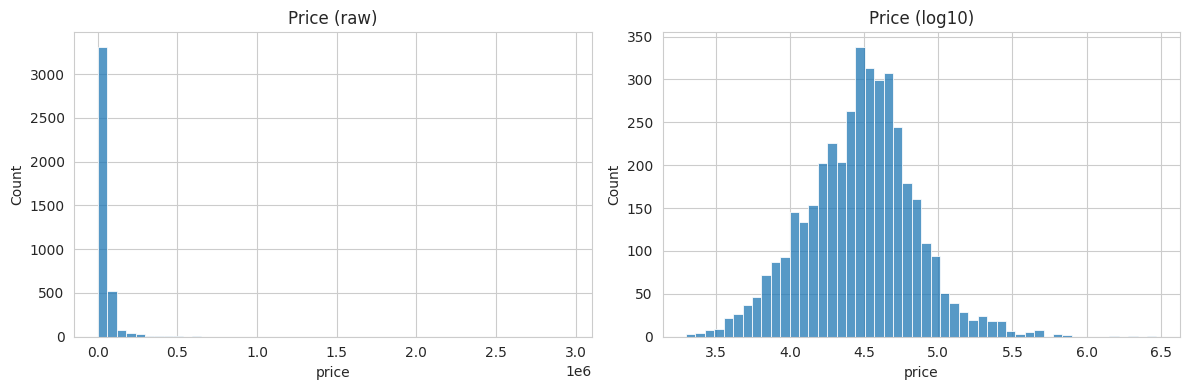

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['price'], bins=50, ax=ax[0])
ax[0].set_title('Price (raw)')
sns.histplot(np.log10(df['price']), bins=50, ax=ax[1])
ax[1].set_title('Price (log10)')
plt.tight_layout()
plt.show()

In [ ]:
print('Skewness of price:', round(df['price'].skew(), 2))

Skewness of price: 19.51


Observation: price is extremely right-skewed. The median is about $31,000, but a few exotic cars (Bugatti, Rolls-Royce, Ferrari) pull the max to almost $3 million. This matters for the outlier step and for choosing the model.

## 1.7 Prediction goal
Goal: predict the listing price of a used car from its age, mileage, brand, fuel type, engine power, and condition (accident history). This is a regression problem. A model like this could help a buyer judge whether a listing is fairly priced, or help a seller choose an asking price.

# 2. Basic Data Cleaning

## 2.1 Drop unwanted features
model has 1,898 unique values for only 4,009 rows (most appear once or twice). It is too specific to learn from, and brand already carries most of that information, so I drop it.

In [ ]:
df = df.drop(columns=['model'])
df.columns.tolist()

['brand',
 'model_year',
 'milage',
 'fuel_type',
 'engine',
 'transmission',
 'ext_col',
 'int_col',
 'accident',
 'clean_title',
 'price']

## 2.2 Convert milage text to a number (and fix the spelling of the column name)

In [ ]:
df = df.rename(columns={'milage': 'mileage'})
df['mileage'] = df['mileage'].str.replace('[^0-9]', '', regex=True).astype(float)
df['mileage'].describe().round(0)

,mileage
count,4009.0
mean,64718.0
std,52297.0
min,100.0
25%,23044.0
50%,52775.0
75%,94100.0
max,405000.0


## 2.3 Pull numeric features out of the engine text
The engine column is free text such as 300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability. I extract horsepower and engine size (liters) with regular expressions.

In [ ]:
df['horsepower'] = df['engine'].str.extract(r'(\d+\.?\d*)\s*HP', flags=re.I)[0].astype(float)
df['engine_liters'] = df['engine'].str.extract(r'(\d+\.?\d*)\s*(?:L\b|Liter)', flags=re.I)[0].astype(float)
df[['engine', 'horsepower', 'engine_liters']].head(8)

,engine,horsepower,engine_liters
0,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,300.0,3.7
1,3.8L V6 24V GDI DOHC,NaN,3.8
2,3.5 Liter DOHC,NaN,3.5
3,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,354.0,3.5
4,2.0L I4 16V GDI DOHC Turbo,NaN,2.0
5,2.4 Liter,NaN,2.4
6,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,292.0,2.0
7,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,282.0,4.4


In [ ]:
df[['horsepower', 'engine_liters']].isna().sum()

,0
horsepower,808
engine_liters,217


## 2.4 Find hidden missing values

In [ ]:
placeholders = ['–', 'not supported']
for col in ['fuel_type', 'engine', 'int_col', 'ext_col', 'transmission']:
    print(col, '->', df[col].isin(placeholders).sum(), 'placeholder rows')

fuel_type -> 47 placeholder rows
engine -> 45 placeholder rows
int_col -> 133 placeholder rows
ext_col -> 15 placeholder rows
transmission -> 4 placeholder rows


In [ ]:
df = df.replace(placeholders, np.nan)
df.isna().sum()

,0
brand,0
model_year,0
mileage,0
fuel_type,217
engine,45
transmission,4
ext_col,15
int_col,133
accident,113
clean_title,596


## 2.5 Address missing values
Looking at *which* rows are missing fuel type shows a pattern: most are electric cars (Tesla, Rivian), whose engine text says "Electric Motor". I can fill those in properly instead of guessing.

In [ ]:
elec = df['engine'].str.contains('Electric Motor', case=False, na=False) | (df['fuel_type'].isna() & df['engine'].eq('Electric'))
print('Electric-looking rows with missing fuel_type:', (elec & df['fuel_type'].isna()).sum())
df.loc[elec & df['fuel_type'].isna(), 'fuel_type'] = 'Electric'
df.loc[elec, 'engine_liters'] = df.loc[elec, 'engine_liters'].fillna(0)   # electric motors have no displacement
df.isna().sum()

Electric-looking rows with missing fuel_type: 166


,0
brand,0
model_year,0
mileage,0
fuel_type,51
engine,45
transmission,4
ext_col,15
int_col,133
accident,113
clean_title,596


Remaining handling:
- clean_title is only ever "Yes" or blank, so a blank means the listing did not state a clean title. I fill it with "No".
- accident is missing for a small number of rows. I drop those rows rather than guess.
- Remaining missing fuel_type, engine-derived values and colors are few, so I drop rows missing fuel_type, and fill horsepower / engine_liters with the median.

In [ ]:
df['clean_title'] = df['clean_title'].fillna('No')
df = df.dropna(subset=['accident', 'fuel_type'])
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())
df['engine_liters'] = df['engine_liters'].fillna(df['engine_liters'].median())
df['int_col'] = df['int_col'].fillna('Unknown')
df['ext_col'] = df['ext_col'].fillna('Unknown')
df = df.drop(columns=['engine'])
df.isna().sum()

,0
brand,0
model_year,0
mileage,0
fuel_type,0
transmission,2
ext_col,0
int_col,0
accident,0
clean_title,0
price,0


In [ ]:
df.shape

(3846, 12)

## 2.6 Remove duplicates

In [ ]:
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates()
df.shape

Duplicate rows: 0


(3846, 12)

## 2.7 Check for inconsistent inputs in categorical variables

In [ ]:
df['transmission'].nunique(), df['transmission'].value_counts().head(10)

(61,
 transmission
 A/T                               993
 8-Speed A/T                       390
 Transmission w/Dual Shift Mode    388
 6-Speed A/T                       354
 6-Speed M/T                       233
 Automatic                         224
 7-Speed A/T                       201
 8-Speed Automatic                 168
 10-Speed A/T                      115
 5-Speed A/T                        83
 Name: count, dtype: int64)

transmission has dozens of spellings for what are really three types. I group them into Automatic, Manual, and Other.

In [ ]:
def group_trans(t):
    t = str(t).upper()
    if 'M/T' in t or 'MANUAL' in t:
        return 'Manual'
    if 'A/T' in t or 'AUTOMATIC' in t or 'CVT' in t or 'DUAL SHIFT' in t:
        return 'Automatic'
    return 'Other'

df['transmission'] = df['transmission'].apply(group_trans)
df['transmission'].value_counts()

,count
transmission,
Automatic,3473
Manual,347
Other,26


In [ ]:
df['fuel_type'].value_counts()

,count
fuel_type,
Gasoline,3218
Hybrid,190
Electric,162
E85 Flex Fuel,133
Diesel,110
Plug-In Hybrid,33


ext_col and int_col have hundreds of near-duplicate color names for example 'Glacier White Metallic'. I keep the most common basic colors and group the rest as 'Other'.

In [ ]:
basic = ['Black', 'White', 'Gray', 'Silver', 'Blue', 'Red']
df['ext_col'] = df['ext_col'].where(df['ext_col'].isin(basic), 'Other')
df['int_col'] = df['int_col'].where(df['int_col'].isin(['Black', 'Beige', 'Gray', 'Brown', 'White']), 'Other')
print(df['ext_col'].value_counts(), '\n')
print(df['int_col'].value_counts())

ext_col
Black     874
White     786
Other     769
Gray      479
Silver    354
Blue      336
Red       248
Name: count, dtype: int64 

int_col
Black    1952
Other     654
Beige     518
Gray      447
Brown     151
White     124
Name: count, dtype: int64


## 2.8 Transform categorical variables into numeric
The two yes/no columns can be turned into 0/1 right away. The multi-category columns (brand, fuel_type, transmission, colors) are encoded as dummy variables in Section 3, after feature selection.

In [ ]:
df['accident'] = (df['accident'] == 'At least 1 accident or damage reported').astype(int)
df['clean_title'] = (df['clean_title'] == 'Yes').astype(int)
df[['accident', 'clean_title']].describe().round(2)

,accident,clean_title
count,3846.00,3846.00
mean,0.25,0.88
std,0.44,0.33
min,0.00,0.00
25%,0.00,1.00
50%,0.00,1.00
75%,1.00,1.00
max,1.00,1.00


## 2.9 Identify outliers with boxplots

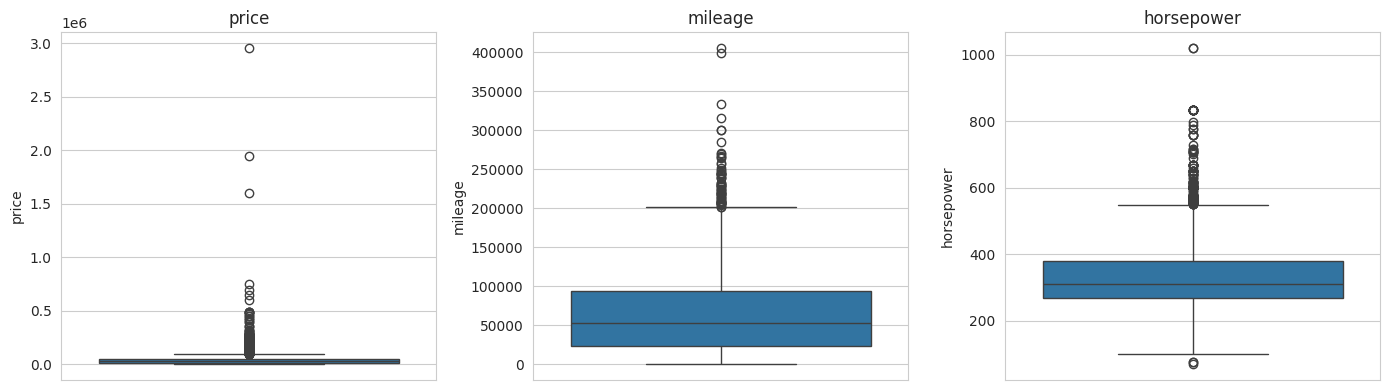

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, c in zip(ax, ['price', 'mileage', 'horsepower']):
    sns.boxplot(y=df[c], ax=a)
    a.set_title(c)
plt.tight_layout()
plt.show()

Price, mileage, and horsepower all show many points beyond the whiskers. I use the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) on price and mileage, since those are the target and the main numeric predictor.

In [ ]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for c in ['price', 'mileage']:
    lo, hi = iqr_bounds(df[c])
    print(f'{c}: lower = {lo:,.0f}, upper = {hi:,.0f}, outliers = {((df[c] < lo) | (df[c] > hi)).sum()}')

price: lower = -31,920, upper = 99,066, outliers = 230
mileage: lower = -83,981, upper = 201,588, outliers = 63


## 2.10 Remove the outliers

In [ ]:
before = len(df)
for c in ['price', 'mileage']:
    lo, hi = iqr_bounds(df[c])
    df = df[(df[c] >= lo) & (df[c] <= hi)]
print(f'Rows before: {before}, after: {len(df)}, removed: {before - len(df)}')

Rows before: 3846, after: 3555, removed: 291


## 2.11 Verify with boxplots and a histogram after cleaning

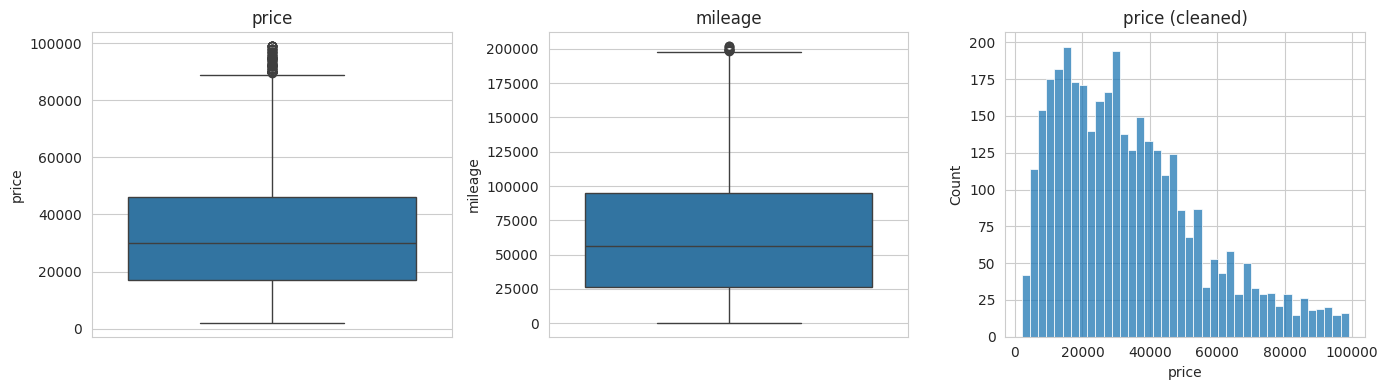

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sns.boxplot(y=df['price'], ax=ax[0]);   ax[0].set_title('price')
sns.boxplot(y=df['mileage'], ax=ax[1]); ax[1].set_title('mileage')
sns.histplot(df['price'], bins=40, ax=ax[2]); ax[2].set_title('price (cleaned)')
plt.tight_layout()
plt.show()

In [ ]:
print('Skewness of price after cleaning:', round(df['price'].skew(), 2))

Skewness of price after cleaning: 0.86


## 2.12 Final check of the cleaned data

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3555 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   brand          3555 non-null   object 
 1   model_year     3555 non-null   int64  
 2   mileage        3555 non-null   float64
 3   fuel_type      3555 non-null   object 
 4   transmission   3555 non-null   object 
 5   ext_col        3555 non-null   object 
 6   int_col        3555 non-null   object 
 7   accident       3555 non-null   int64  
 8   clean_title    3555 non-null   int64  
 9   price          3555 non-null   float64
 10  horsepower     3555 non-null   float64
 11  engine_liters  3555 non-null   float64
dtypes: float64(4), int64(3), object(5)
memory usage: 361.1+ KB


In [ ]:
df = df.reset_index(drop=True)
df.to_csv('used_cars_cleaned.csv', index=False)
df.head()

,brand,model_year,mileage,fuel_type,transmission,ext_col,int_col,accident,clean_title,price,horsepower,engine_liters
0,Ford,2013,51000.0,E85 Flex Fuel,Automatic,Black,Black,1,1,10300.0,300.0,3.7
1,Hyundai,2021,34742.0,Gasoline,Automatic,Other,Gray,1,1,38005.0,310.0,3.8
2,Lexus,2022,22372.0,Gasoline,Automatic,Blue,Black,0,0,54598.0,310.0,3.5
3,INFINITI,2015,88900.0,Hybrid,Automatic,Black,Black,0,1,15500.0,354.0,3.5
4,Audi,2021,9835.0,Gasoline,Automatic,Other,Black,0,0,34999.0,310.0,2.0


# 3. Feature Engineering

## 3.1 Create a new feature: car_age
A car's age is easier for a model (and for people) to reason about than the raw model year. The newest year in the data is 2024, so car_age = 2024 − model_year. The original model_year is then dropped because it carries the same information.

In [ ]:
df['car_age'] = 2024 - df['model_year']
df = df.drop(columns=['model_year'])
df['car_age'].describe().round(1)

,car_age
count,3555.0
mean,8.4
std,5.7
min,0.0
25%,4.0
50%,7.0
75%,12.0
max,28.0


## 3.2 Feature selection: look for variables with zero or little variance

In [ ]:
num_cols = ['car_age', 'mileage', 'horsepower', 'engine_liters']
df[num_cols].var().round(1)

,0
car_age,3.250000e+01
mileage,2.206984e+09
horsepower,1.096220e+04
engine_liters,2.400000e+00


No numeric column has zero variance. (The raw variance numbers look very different only because the columns are on different scales: mileage is in the tens of thousands, engine size is in single digits.)

For categorical columns, I check how much of the data falls in the single most common category. A column where one value is almost everything gives the model very little to learn from.

In [ ]:
cat_cols = ['brand', 'fuel_type', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']
share = {c: round(df[c].value_counts(normalize=True).iloc[0], 3) for c in cat_cols}
pd.Series(share, name='share of most common value').sort_values(ascending=False)

,share of most common value
transmission,0.903
clean_title,0.883
fuel_type,0.834
accident,0.736
int_col,0.513
ext_col,0.228
brand,0.099


## 3.3 Feature selection with graphs: how do features relate to price?

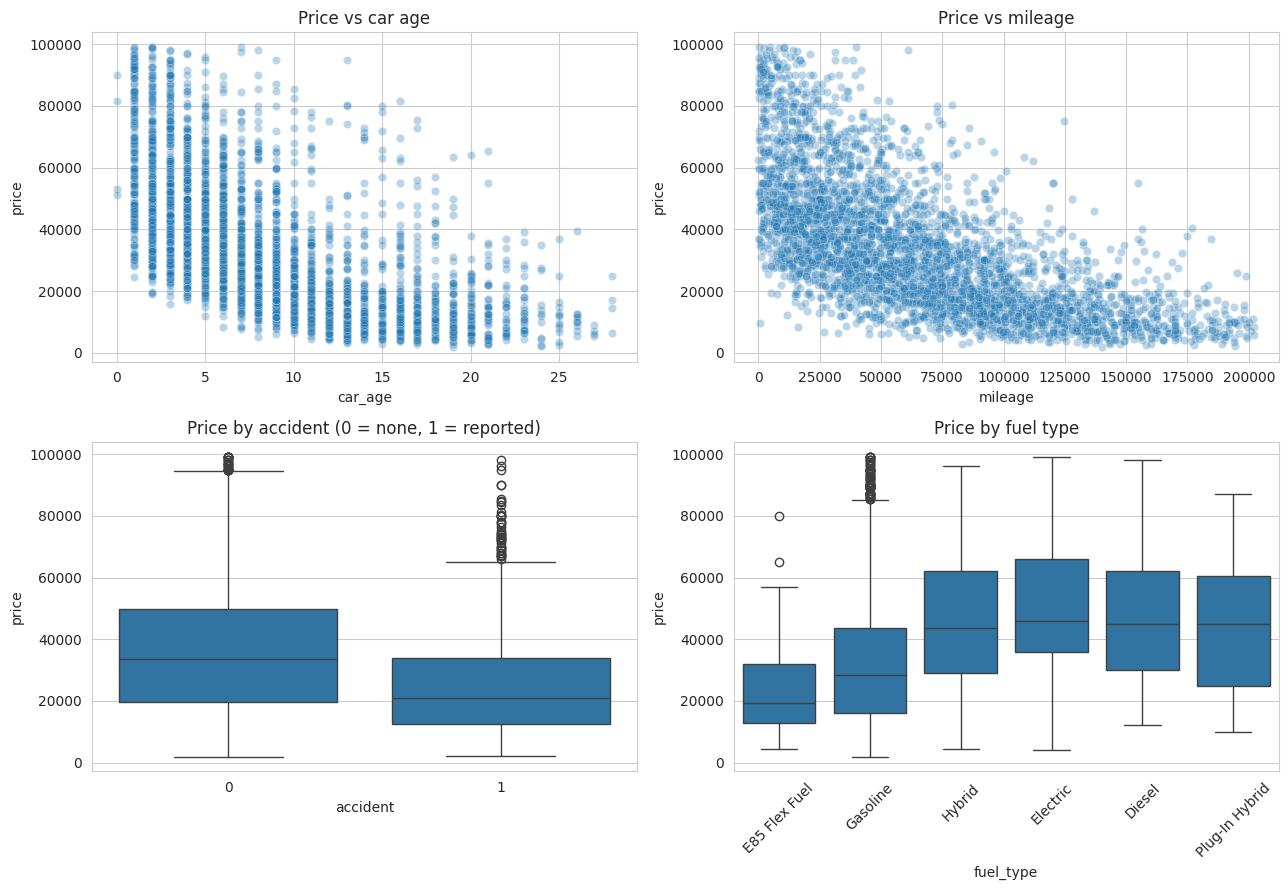

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.scatterplot(data=df, x='car_age', y='price', alpha=0.3, ax=ax[0, 0]);   ax[0, 0].set_title('Price vs car age')
sns.scatterplot(data=df, x='mileage', y='price', alpha=0.3, ax=ax[0, 1]);   ax[0, 1].set_title('Price vs mileage')
sns.boxplot(data=df, x='accident', y='price', ax=ax[1, 0]);                 ax[1, 0].set_title('Price by accident (0 = none, 1 = reported)')
sns.boxplot(data=df, x='fuel_type', y='price', ax=ax[1, 1]);                ax[1, 1].set_title('Price by fuel type')
ax[1, 1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## 3.4 ANOVA F-test: categorical features vs. the numeric target
The one-way ANOVA F-test compares the average price across the groups of a category (for example, average price of gasoline vs. hybrid vs. electric cars).
- A large F-score and small p-value (< 0.05) means the group averages really differ, so the feature helps explain price and is kept.
- A small F-score and large p-value (≥ 0.05) means the groups have about the same average price, so the feature is irrelevant to the target and is removed.

In [ ]:
from scipy.stats import f_oneway

rows = []
for c in cat_cols:
    groups = [g['price'].values for _, g in df.groupby(c) if len(g) > 1]
    F, p = f_oneway(*groups)
    rows.append({'feature': c, 'F_score': round(F, 2), 'p_value': p})

anova = pd.DataFrame(rows).sort_values('F_score', ascending=False).reset_index(drop=True)
anova['p_value'] = anova['p_value'].map(lambda v: f'{v:.2e}')
anova

,feature,F_score,p_value
0,accident,212.11,1.03e-46
1,clean_title,122.90,4.22e-28
2,int_col,56.65,7.71e-57
3,fuel_type,51.84,4.76e-52
4,brand,17.17,3.59e-121
5,transmission,12.02,6.28e-06
6,ext_col,10.97,3.78e-12


## 3.5 Chi-squared test between two categorical features
A chi-squared test needs two categorical variables. Since the target (price) is numeric, I can't use it against the target. Instead I use it to check whether two *features* are redundant with each other: here, accident and clean_title.
A small p-value means they are related (dependent).

In [ ]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df['accident'], df['clean_title'])
print(table, '\n')
chi2, p, dof, _ = chi2_contingency(table)
print(f'chi2 = {chi2:.2f}, p-value = {p:.4f}')

clean_title    0     1
accident              
0            376  2242
1             41   896 

chi2 = 65.50, p-value = 0.0000


## 3.6 Correlation between numeric features
I look for (1) numeric features that are weakly related to price and (2) pairs of features so highly correlated (above about 0.8) that they repeat each other.

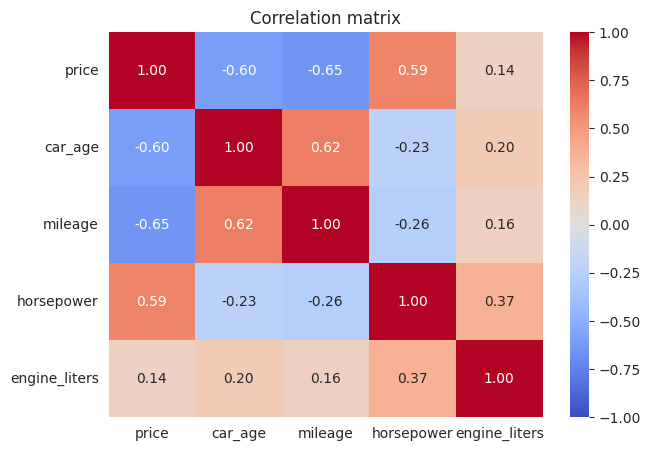

In [ ]:
corr = df[['price'] + num_cols].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix')
plt.show()

In [ ]:
corr['price'].drop('price').sort_values(key=abs, ascending=False).round(2)

,price
mileage,-0.65
car_age,-0.60
horsepower,0.59
engine_liters,0.14


In [ ]:
pairs = corr.loc[num_cols, num_cols].where(np.triu(np.ones((len(num_cols), len(num_cols))), k=1).astype(bool)).stack().dropna()
print(pairs.round(2), '\n')
high = pairs[abs(pairs) > 0.8]
print('Pairs with |correlation| above 0.8:', 'none' if high.empty else '\n' + str(high.round(2)))

car_age     mileage          0.62
            horsepower      -0.23
            engine_liters    0.20
mileage     horsepower      -0.26
            engine_liters    0.16
horsepower  engine_liters    0.37
dtype: float64 

Pairs with |correlation| above 0.8: none


Reading the results.
- Price is moderately correlated with mileage (negative), car age (negative), and horsepower (positive). Older, higher-mileage cars cost less, and more powerful cars cost more. engine_liters is only weakly related (about 0.14), but it is not removed because a model can still use it together with horsepower.
- No pair of numeric features is above 0.8, so none repeat each other enough to drop. Car age and mileage are the closest pair, which makes sense (older cars have more miles), but they are still different enough to keep both.

## 3.7 Drop the irrelevant features
Rule from the ANOVA test: drop any categorical feature with p-value ≥ 0.05. Since every feature passed, nothing is removed here. The code is still included so the rule is applied automatically.

Reading the ANOVA results. Every feature has a p-value far below 0.05, so the average price really does differ across the groups of each feature. accident and clean_title have the largest F-scores. ext_col has the smallest F-score, but it is still significant, so it passes the test. (With about 3,500 rows, even small differences tend to be statistically significant, so the F-score is the better guide to which features matter most.)

The chi-squared result says accident and clean_title are related, but they are not duplicates of each other: the table shows plenty of rows in every combination, so I keep both.

In [ ]:
anova_p = {r['feature']: float(r['p_value']) for _, r in anova.iterrows()}
to_drop = [c for c, p in anova_p.items() if p >= 0.05]
print('Dropping:', to_drop)
df = df.drop(columns=to_drop)
df.columns.tolist()

Dropping: []


['brand',
 'mileage',
 'fuel_type',
 'transmission',
 'ext_col',
 'int_col',
 'accident',
 'clean_title',
 'price',
 'horsepower',
 'engine_liters',
 'car_age']

## 3.8 Prepare categorical variables: group rare brands, then create dummy variables
Machine-learning models need numbers, and brand, fuel_type, transmission (and any color column that survived) have no natural order, so a number code like 1, 2, 3 would suggest a false ranking. Dummy (one-hot) variables avoid that. I use drop_first=True to avoid the dummy variable trap (one category becomes the baseline).

brand has 57 values and some brands appear only a few times, so brands with fewer than 15 listings are grouped as 'Other' to avoid many nearly empty columns.

In [ ]:
counts = df['brand'].value_counts()
rare = counts[counts < 15].index
print('Brands grouped as Other:', len(rare))
df['brand'] = df['brand'].where(~df['brand'].isin(rare), 'Other')
df['brand'].nunique()

Brands grouped as Other: 16


38

In [ ]:
dummy_cols = [c for c in ['brand', 'fuel_type', 'transmission', 'ext_col', 'int_col'] if c in df.columns]
print('Columns turned into dummies:', dummy_cols)
df_model = pd.get_dummies(df, columns=dummy_cols, drop_first=True, dtype=int)
df_model.shape

Columns turned into dummies: ['brand', 'fuel_type', 'transmission', 'ext_col', 'int_col']


(3555, 62)

In [ ]:
df_model.head()

,mileage,accident,clean_title,price,horsepower,engine_liters,car_age,brand_Alfa,brand_Audi,brand_BMW,brand_Buick,brand_Cadillac,brand_Chevrolet,brand_Chrysler,brand_Dodge,brand_Ford,brand_GMC,brand_Genesis,brand_Honda,brand_Hummer,brand_Hyundai,brand_INFINITI,brand_Jaguar,brand_Jeep,brand_Kia,brand_Land,brand_Lexus,brand_Lincoln,brand_MINI,brand_Maserati,brand_Mazda,brand_Mercedes-Benz,brand_Mitsubishi,brand_Nissan,brand_Other,brand_Pontiac,brand_Porsche,brand_RAM,brand_Rivian,brand_Subaru,brand_Tesla,brand_Toyota,brand_Volkswagen,brand_Volvo,fuel_type_E85 Flex Fuel,fuel_type_Electric,fuel_type_Gasoline,fuel_type_Hybrid,fuel_type_Plug-In Hybrid,transmission_Manual,transmission_Other,ext_col_Blue,ext_col_Gray,ext_col_Other,ext_col_Red,ext_col_Silver,ext_col_White,int_col_Black,int_col_Brown,int_col_Gray,int_col_Other,int_col_White
0,51000.0,1,1,10300.0,300.0,3.7,11,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
1,34742.0,1,1,38005.0,310.0,3.8,3,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0
2,22372.0,0,0,54598.0,310.0,3.5,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0
3,88900.0,0,1,15500.0,354.0,3.5,9,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0
4,9835.0,0,0,34999.0,310.0,2.0,3,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0


## 3.9 Feature scaling
Does the algorithm need it? It depends on the model I choose in Section 4.
- Linear Regression / Ridge / Lasso, KNN, SVR: yes, they work best with standardized data (mean 0, standard deviation 1), because features like mileage (tens of thousands) would otherwise dominate features like engine size (single digits).
- Decision tree / Random Forest: no, trees split on thresholds, so scaling doesn't matter.

I standardize only the numeric columns (dummy 0/1 columns are left alone). The price target is not scaled. Below I show what standardizing does to the numeric columns. In Section 4, the scaler will be fit on the training set only (inside a pipeline), so no information from the test set leaks into the model.

In [ ]:
from sklearn.preprocessing import StandardScaler

before = df_model[num_cols].describe().loc[['mean', 'std']].round(2)
demo = pd.DataFrame(StandardScaler().fit_transform(df_model[num_cols]), columns=num_cols)
after = demo.describe().loc[['mean', 'std']].round(2)
print('BEFORE scaling'); print(before, '\n')
print('AFTER scaling');  print(after)

BEFORE scaling
      car_age   mileage  horsepower  engine_liters
mean     8.41  65188.51      321.48           3.47
std      5.71  46978.55      104.70           1.56 

AFTER scaling
      car_age  mileage  horsepower  engine_liters
mean     -0.0     -0.0        -0.0           -0.0
std       1.0      1.0         1.0            1.0


## 3.10 Final feature set

In [ ]:
X = df_model.drop(columns=['price'])
y = df_model['price']
print('Features (X):', X.shape, '| Target (y):', y.shape)
df_model.to_csv('used_cars_features.csv', index=False)

Features (X): (3555, 61) | Target (y): (3555,)


# 4. Build the Prediction Model

## 4.1 Does this data need to be balanced?
No. Balancing (oversampling, undersampling, SMOTE) is for classification problems where one class is much rarer than another. Here the target price is a continuous number, so there are no classes to balance. The thing to watch instead is the skew of the target, which I handled by removing extreme outliers in Section 2.

In [ ]:
print('Target skewness:', round(y.skew(), 2))
y.describe().round(0)

Target skewness: 0.86


,price
count,3555.0
mean,33940.0
std,21261.0
min,2000.0
25%,17000.0
50%,29998.0
75%,45999.0
max,99000.0


## 4.2 Split the data: train_test_split and cross-validation
I use both:
1. train_test_split (80% train / 20% test): the test set is held back and used once at the end, to estimate how the model does on cars it has never seen.
2. 5-fold cross-validation on the training set: checks that the score is stable and not just lucky for one particular split.

random_state=42 makes the split repeatable.

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (2844, 61) | Test: (711, 61)


## 4.3 Choose the algorithms
- Baseline (predict the average price): every model should beat this. If it doesn't, it has learned nothing.
- Linear Regression: fits a straight-line equation price = b0 + b1·age + b2·mileage + ... by choosing the coefficients that minimize the sum of squared errors between predicted and actual prices. It is simple and easy to interpret, but it assumes each feature affects price in a straight line, and it needs standardized numeric features.
- Random Forest: builds many decision trees, each trained on a random sample of the rows and a random subset of features, and averages their predictions. It can capture curves and interactions (for example, mileage matters more for a luxury car than for an economy car) and does not need scaling.

Scaling is done inside a pipeline so the scaler is fit on the training data only.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

num_cols = ['car_age', 'mileage', 'horsepower', 'engine_liters']
results = []

def evaluate(name, model):
    tr, te = model.predict(X_train), model.predict(X_test)
    row = {
        'model': name,
        'train_R2': r2_score(y_train, tr), 'test_R2': r2_score(y_test, te),
        'test_MAE': mean_absolute_error(y_test, te),
        'test_RMSE': np.sqrt(mean_squared_error(y_test, te)),
    }
    results.append(row)
    return pd.DataFrame([row]).round(3).set_index('model')

## 4.4 Metrics used to evaluate the models
- R² (r-squared): the share of the variation in price the model explains. 1.0 is perfect, 0 means no better than guessing the average.
- MAE (mean absolute error): the average miss, in dollars. Easy to explain.
- RMSE (root mean squared error): also in dollars, but it punishes big misses more.
I report R² on both train and test; a big gap (high train, low test) would mean overfitting.

## 4.5 Baseline: always predict the average price

In [ ]:
baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)
evaluate('Baseline (mean)', baseline)

,train_R2,test_R2,test_MAE,test_RMSE
model,,,,
Baseline (mean),0.0,-0.001,17003.482,21409.561


## 4.6 Model 1: Linear Regression (with standardized numeric features)

In [ ]:
prep = ColumnTransformer([('scale', StandardScaler(), num_cols)], remainder='passthrough')
lin = Pipeline([('prep', prep), ('model', LinearRegression())]).fit(X_train, y_train)
evaluate('Linear Regression', lin)

,train_R2,test_R2,test_MAE,test_RMSE
model,,,,
Linear Regression,0.745,0.743,8125.262,10845.282


## 4.7 Model 2: Random Forest

In [ ]:
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train, y_train)
evaluate('Random Forest', rf)

,train_R2,test_R2,test_MAE,test_RMSE
model,,,,
Random Forest,0.979,0.838,5872.461,8617.811


## 4.8 5-fold cross-validation (R² on the training data)

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv = {}
for name, mdl in [('Linear Regression', lin), ('Random Forest', rf)]:
    sc = cross_val_score(mdl, X_train, y_train, cv=kf, scoring='r2')
    cv[name] = sc
    print(f'{name}: fold R² = {np.round(sc, 3)} | mean = {sc.mean():.3f} | std = {sc.std():.3f}')

Linear Regression: fold R² = [0.738 0.734 0.733 0.738 0.721] | mean = 0.733 | std = 0.006
Random Forest: fold R² = [0.847 0.826 0.827 0.846 0.846] | mean = 0.838 | std = 0.010


## 4.9 Compare all models

In [ ]:
pd.DataFrame(results).round(3).set_index('model')

,train_R2,test_R2,test_MAE,test_RMSE
model,,,,
Baseline (mean),0.000,-0.001,17003.482,21409.561
Linear Regression,0.745,0.743,8125.262,10845.282
Random Forest,0.979,0.838,5872.461,8617.811


## 4.10 Predicted vs. actual prices (test set)

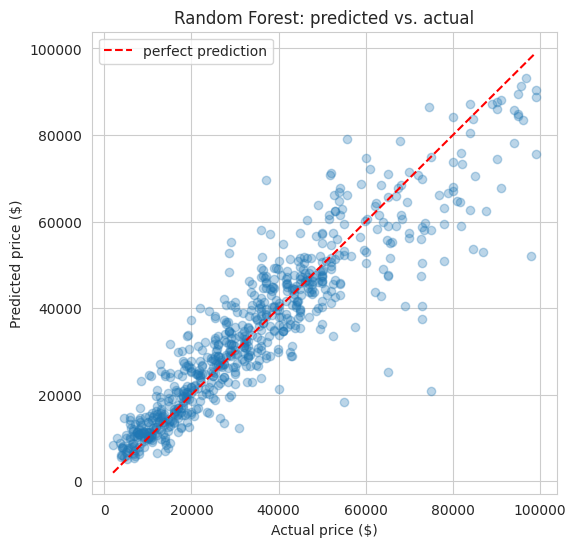

In [ ]:
best_pred = rf.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=0.3)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--', label='perfect prediction')
plt.xlabel('Actual price ($)'); plt.ylabel('Predicted price ($)')
plt.title('Random Forest: predicted vs. actual')
plt.legend()
plt.show()

## 4.11 Which features matter most?

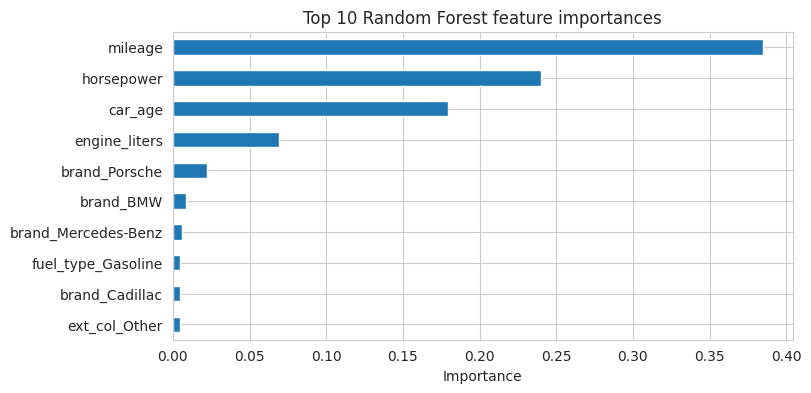

In [ ]:
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 4))
imp[::-1].plot(kind='barh')
plt.title('Top 10 Random Forest feature importances')
plt.xlabel('Importance')
plt.show()

## 4.12 Results and interpretation

| Model | Test R² | Test MAE | Test RMSE |
|---|---|---|---|
| Baseline (mean) | −0.00 | $17,003 | $21,410 |
| Linear Regression | 0.74 | $8,125 | $10,845 |
| Random Forest | 0.84 | $5,872 | $8,618 |

Best model: Random Forest. It explains about 84% of the variation in used-car prices, and its typical miss (MAE) is about $5,900 on cars that average about $34,000. Both models clearly beat the baseline, so they learned real patterns. Cross-validation scores (Linear 0.73, Random Forest 0.84, with very small spread between folds) match the test scores, so the results are not a lucky split.

Why Random Forest beat Linear Regression: price does not fall in a straight line with age or mileage (new cars lose value fastest), and the effect of a feature depends on the car (mileage matters differently for a Porsche than for a Ford). Trees can capture that; a single straight-line equation cannot.

Overfitting check: the Random Forest scores 0.98 on the training data but 0.84 on the test data. That gap means it memorizes some of the training cars. Cross-validation shows the 0.84 holds up on unseen data, but limiting tree depth or using more regularization could narrow the gap. Linear Regression has nearly identical train and test scores (0.745 vs 0.743), so it is not overfitting; it is simply too simple to go higher.

Most important features: mileage, horsepower, and car age together account for most of the Random Forest's decisions. Brand matters mainly for luxury makes such as Porsche.

Why the model is not more accurate. An R² of 0.84 is good, but the remaining 16% is unexplained. Likely reasons:
- I dropped the model column (it had 1,898 unique values), so the model cannot tell a base trim from a top trim of the same brand.
- About 20% of rows had no horsepower in the engine text, so I filled them with the median, which blurs that feature.
- The data has no information on options, condition beyond the accident flag, or location.
- The target is the asking price, not the final sale price, so sellers' pricing habits add noise.
- I removed exotic and very expensive cars as outliers, so this model should not be used to price them.

Possible next steps: tune the Random Forest (max_depth, min_samples_leaf), try Gradient Boosting, or extract a trim keyword from model.